In [1]:
%pylab inline

%load_ext autoreload
%autoreload 2

%load_ext julia.magic
%julia using CMBLensing

import sys
sys.path.append("/home/cailmdaley/work/ultradeep100d")
from CMBLensing_spt3g_interface import toFlatSkyMap
from julia_jlcommand import jl

from spt3g.core import G3Units
from spt3g.coordinateutils import FlatSkyMap, MapProjection
from spt3g.mapspectra.map_spectrum_classes import MapSpectrum2D
from spt3g.mapspectra.map_analysis import flatten_pol, constructEB
from spt3g.mapspectra.apodmask import make_border_apodization

def plotframe(frame, layout=121, size=(13,5), suptitle=None):
    
    fig = figure(figsize=size, tight_layout=True)
    fig.suptitle(suptitle, y=1.08)
    
    for i, k in enumerate(frame.keys()):
        subplot(layout + i)
        m = frame[k] if type(frame[k]) is not MapSpectrum2D else frame[k].get_real().get_rmap()['T']
        matshow(m, 0, cmap="RdBu_r") 
        title(k); xticks([]); yticks([]); colorbar(); 

Populating the interactive namespace from numpy and matplotlib
Initializing Julia interpreter. This may take some time...


# Accuracy of Polarization Handling in 3G software

I've been working on a delensing module for 3G software, using Healpix sims as ground truth.  
When making EB `FlatSkyMaps` from unlensed Healpix maps, I notice weird artifacts in the B-mode map:

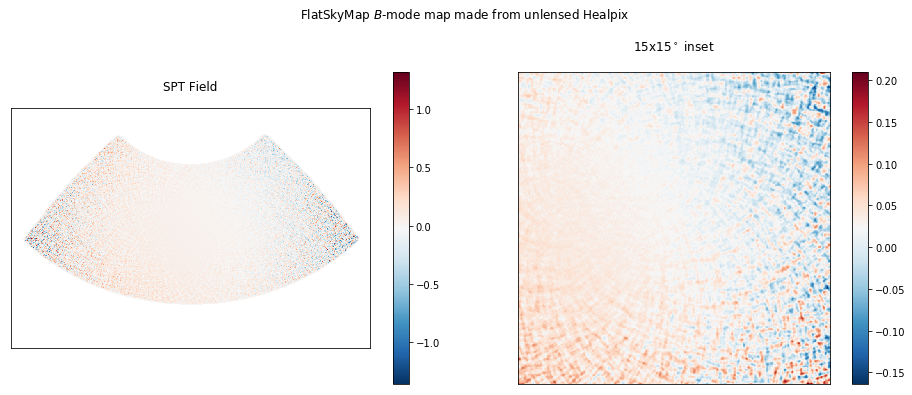

In [3]:
from sim_reader import LensingSimReader
sim_reader = LensingSimReader()

teb_unlensed = sim_reader.get_sim_teb(lensed=False)
mask = sim_reader.get_pixel_mask(); mask[mask==0] = np.nan

plotframe(
    {'SPT Field':             teb_unlensed['B'].get_real().get_rmap()['T'] * mask / G3Units.uK, 
     r'15x15$^\circ$ inset':  np.array(teb_unlensed['B'].get_real().get_rmap()['T'])[550:1000, 1000:1450] / G3Units.uK},
    suptitle=r"FlatSkyMap $B$-mode map made from unlensed Healpix")

Since the unlensed Healpix maps have no B-mode, this is due entirely to numerical effects.
There are two possible culprits, `flatten_pol` ([source code](https://github.com/SouthPoleTelescope/spt3g_software/blob/master/mapspectra/python/map_analysis.py#L21)) and the $E \to B$ leakage estimator used in `constructEB` ([source code](https://github.com/SouthPoleTelescope/spt3g_software/blob/master/mapspectra/python/map_analysis.py#L277)).


Let's first look at how accurate `constructEB` is.

---

## `constructEB`

I've done some tests using maps from Marius' `CMBLensing` as a reference; these maps have almost-zero $B$-mode power, and are already flat sky, allowing us to isolate the problem better.

The original `CMBLensing` $Q, U, E,$ and $B$ maps:

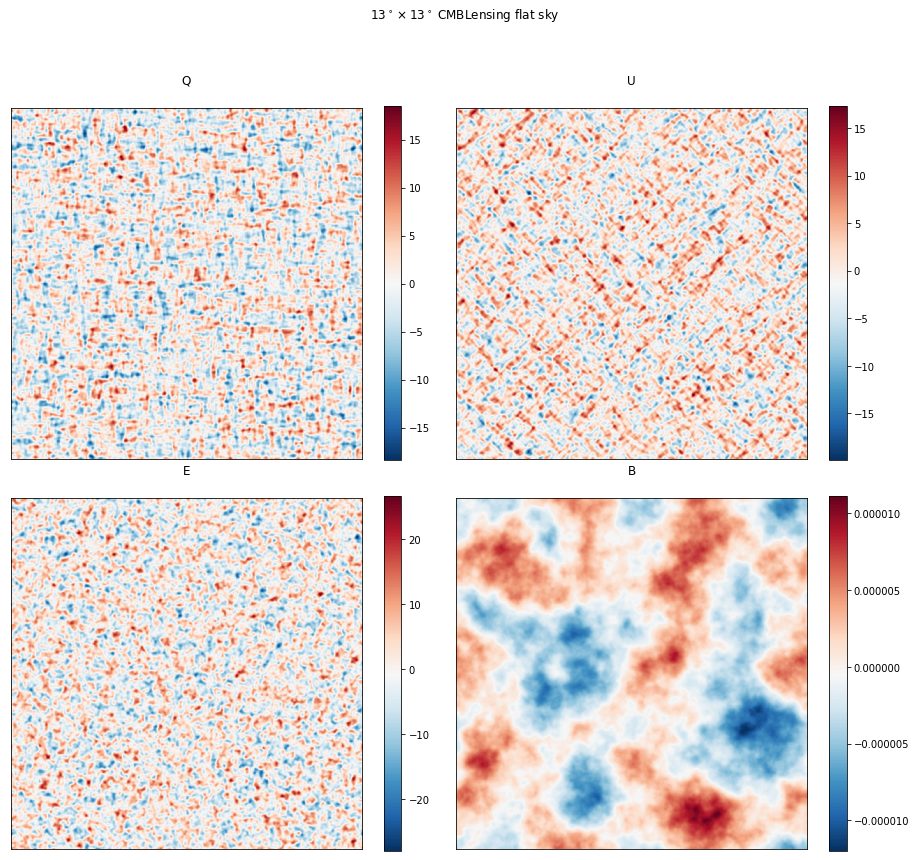

In [3]:
f = jl('load_sim_dataset(θpix=0.5, Nside=780*2, T=Float64, pol=:P, rfid=1e-10).f');

maps_cmbl = {k : toFlatSkyMap(jl('Map($f[Symbol($k)])')) for k in 'QUEB'}
plotframe(maps_cmbl, layout=221, size=(13,11), suptitle=r"$13^\circ \times 13^\circ$ CMBLensing flat sky")

These maps already match 3G software's polarization convention, so we can call `constructEB` on them immediately.  

### No Apodization

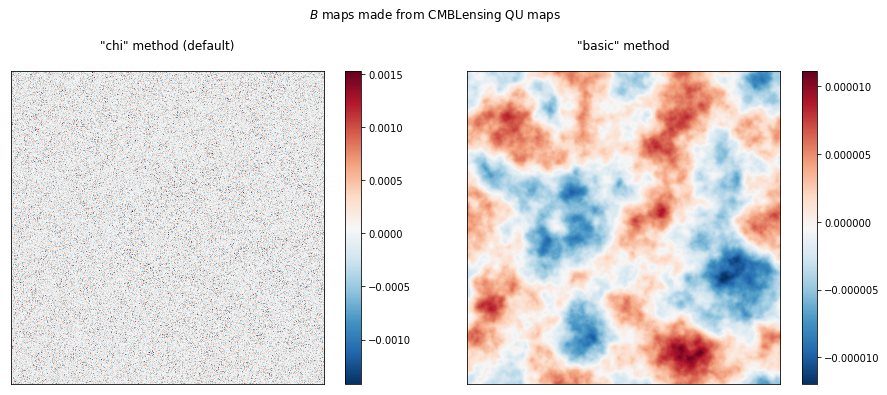

In [4]:
plotframe(
    {'"chi" method (default)': constructEB(maps_cmbl, b_mode_method='chi')['B'],
     '"basic" method': constructEB(maps_cmbl, b_mode_method='basic')['B']},
    suptitle=r"$B$ maps made from CMBLensing QU maps")

### Apodization Mask

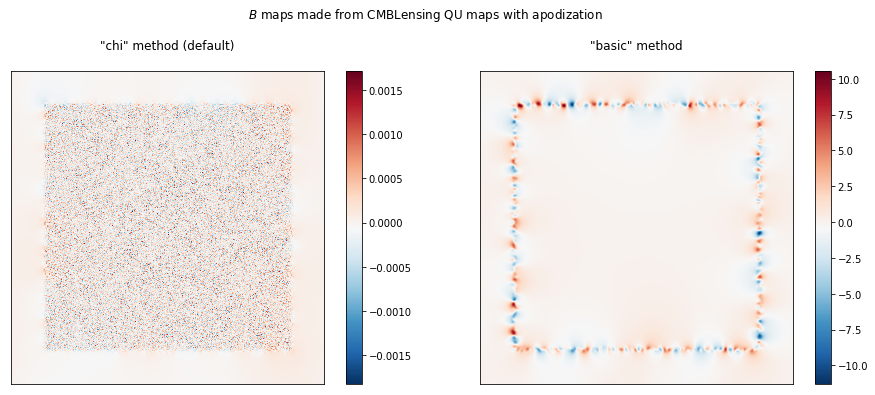

In [5]:
bw = maps_cmbl['Q'].shape[1] // 10
mask = np.zeros(maps_cmbl['Q'].shape)
mask[bw:-bw, bw:-bw] = 1
mask = make_border_apodization(mask, res=maps_cmbl['Q'].res)

plotframe(
    {'"chi" method (default)': constructEB(maps_cmbl, b_mode_method='chi', apod_mask=mask)['B'],
     '"basic" method': constructEB(maps_cmbl, b_mode_method='basic', apod_mask=mask)['B']},
    suptitle=r"$B$ maps made from CMBLensing QU maps with apodization")

### Resolution scaling

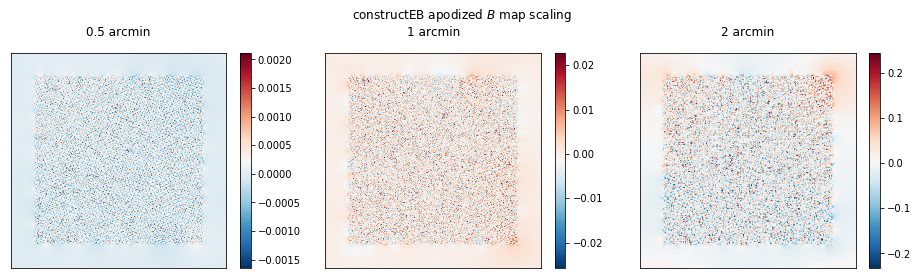

In [6]:
d = {}
for res in [0.5, 1, 2]:
    f = jl('load_sim_dataset(θpix=$res, Nside=Int(600 / $res), T=Float64, pol=:P, rfid=1e-10).f');

    maps_cmbl = {k : toFlatSkyMap(jl('Map($f[Symbol($k)])')) for k in 'QUEB'}
    
    bw = maps_cmbl['Q'].shape[1] // 10
    mask = np.zeros(maps_cmbl['Q'].shape)
    mask[bw:-bw, bw:-bw] = 1
    mask = make_border_apodization(mask, res=maps_cmbl['Q'].res)
    d[str(res) + " arcmin"] = constructEB(maps_cmbl, b_mode_method='chi', apod_mask=mask)['B']
    
plotframe(d, layout=131, size=(13,3.5), suptitle=r"constructEB apodized $B$ map scaling")

It's theoretically possible to call the `chi` estimator at higher order, but doing so raises a `NotImplementedError`.

So the `chi` $E \to B$ estimator introduces a $\sim 0.15\mu$K scatter for 2' pixels---not enough to account for the $\gtrsim 1 \mu$K scatter we saw in the flattened Healpix maps.

## `flatten_pol`

What if we call `flatten_pol` before `constructEB`, even though the maps are already flattened?  
Now I'm making the maps roughly the same size as the SPT3G field (so $75^\circ \times 75^\circ$),

### Resolution scaling

In [5]:
noapod = {}
apod = {}

for res in [1, 2, 4, 8, 10, 16]:
    f = jl('load_sim_dataset(θpix=$res, Nside=Int(4000 / $res), T=Float64, pol=:P, rfid=1e-10).f');
    maps_cmbl = {k : toFlatSkyMap(jl('Map($f[Symbol($k)])')) for k in 'QUEB'}
    flatten_pol(maps_cmbl)
    
    bw = maps_cmbl['Q'].shape[1] // 10
    mask = np.zeros(maps_cmbl['Q'].shape)
    mask[bw:-bw, bw:-bw] = 1
    mask = make_border_apodization(mask, res=maps_cmbl['Q'].res)
    
    noapod[str(res) + " arcmin"] = constructEB(maps_cmbl)['B']
    apod[str(res) + " arcmin"]   = constructEB(maps_cmbl, apod_mask=mask)['B'].get_real().get_rmap()['T'] * mask
    

/src/spt3g_software/build/spt3g/mapspectra/apodmask.py:453: RuntimeWarning: invalid value encountered in true_divide
  mask /= mask.max()
/src/spt3g_software/build/spt3g/mapspectra/apodmask.py:482: RuntimeWarning: invalid value encountered in less
  mask[np.abs(mask) < apod_threshold] = 0.0
/src/spt3g_software/build/spt3g/mapspectra/apodmask.py:483: RuntimeWarning: invalid value encountered in less
  mask[np.abs(mask - 1.0) < apod_threshold] = 1.0


#### No apodization

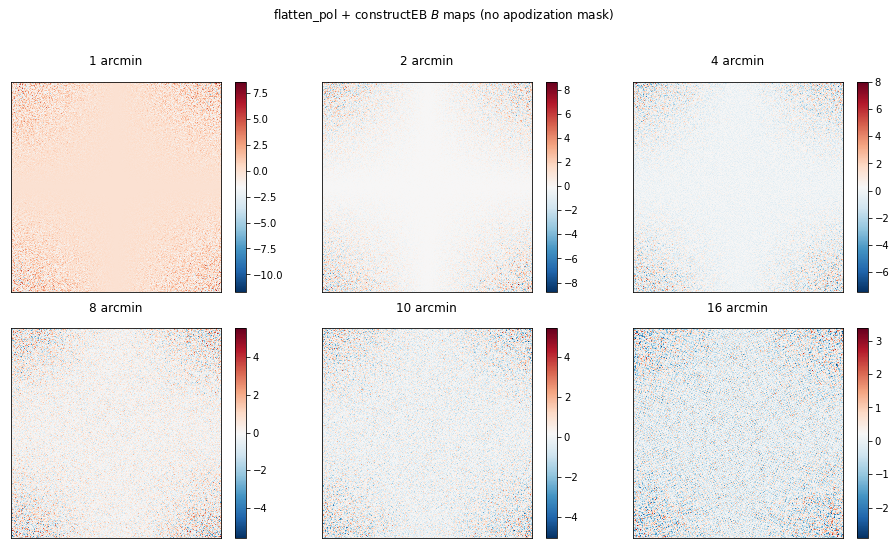

In [6]:
plotframe(noapod, layout=231, size=(13,7), suptitle=r"flatten_pol + constructEB $B$ maps (no apodization mask)")

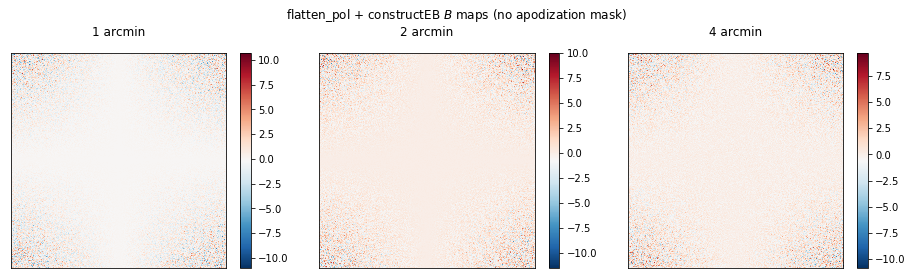

In [8]:
plotframe(noapod, layout=131, size=(13,3.5), suptitle=r"flatten_pol + constructEB $B$ maps (no apodization mask)")

#### Apodization

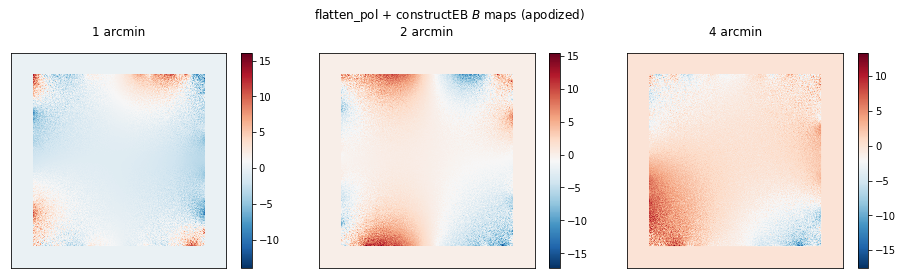

In [9]:
plotframe(apod, layout=131, size=(13,3.5), suptitle=r"flatten_pol + constructEB $B$ maps (apodized)")

So calling `flatten_pol` increases numerical noise dramatically, and seems to really confuse the $E \to B$ leakage estimator in the presence of apodization...  
However, this effect doesn't seem to depend heavily on resolution.

## Putting everything together: SPT field  B maps...

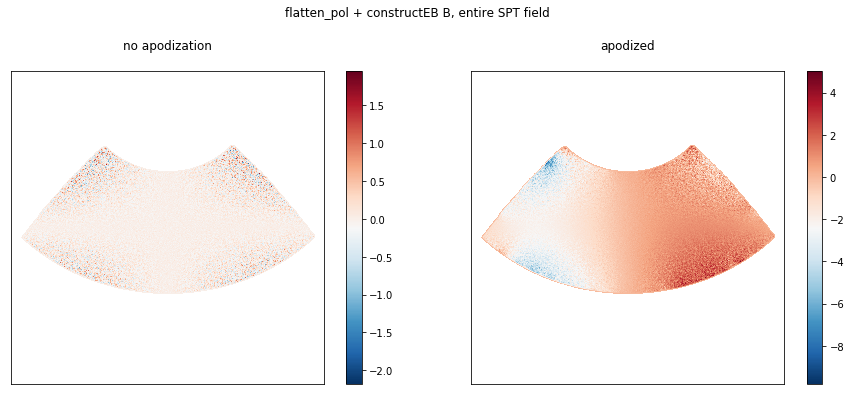

In [49]:
f = jl('load_sim_dataset(θpix=2, Nside=2250, T=Float64, pol=:P, rfid=1e-10).f');
maps_cmbl_big = {k : toFlatSkyMap(jl('Map($f[Symbol($k)])')) for k in 'QUEB'}
flatten_pol(maps_cmbl_big)

spt_mask = np.zeros((2250,2250))
spt_mask[375:1875, :] = sim_reader.get_pixel_mask()
b_big_flat = constructEB(maps_cmbl_big)['B'].get_real().get_rmap()['T']
b_big_flat_apod = constructEB(maps_cmbl_big, apod_mask=spt_mask)['B'].get_real().get_rmap()['T']
spt_mask[spt_mask == 0] = np.nan

plotframe({"no apodization" : b_big_flat * spt_mask, "apodized" : b_big_flat_apod * spt_mask},
          suptitle="flatten_pol + constructEB B, entire SPT field")

In [9]:
from sim_reader import LensingSimReader
sim_reader = LensingSimReader()
teb_unlensed = sim_reader.get_sim_teb(lensed=False)

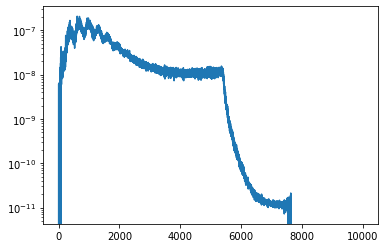

In [13]:
from spt3g.mapspectra.map_analysis import mapffts_to_powerspectra
Cls = mapffts_to_powerspectra(teb_unlensed['B'], calculate_dls=True)
semilogy(Cls['TT'].lbins[1:], Cls['TT'])

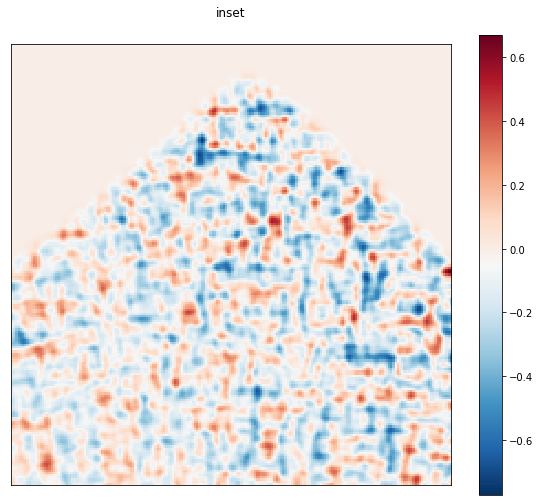

In [43]:
plotframe({"inset" : (teb_unlensed["B"].get_real().get_rmap()['T'] / G3Units.uK * sim_reader.get_pixel_mask())[150:350, 1480:1680]},
          size=(8,7), layout=111)

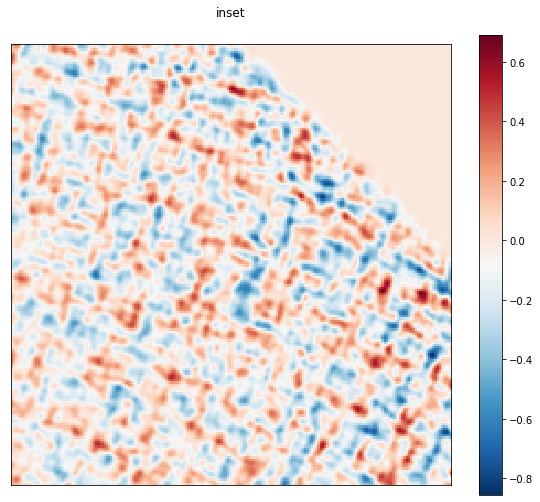

In [5]:
plotframe({"inset" : (teb_unlensed["B"].get_real().get_rmap()['T'] / G3Units.uK * sim_reader.get_pixel_mask())[350:550, 1680:1880]},
          size=(8,7), layout=111)

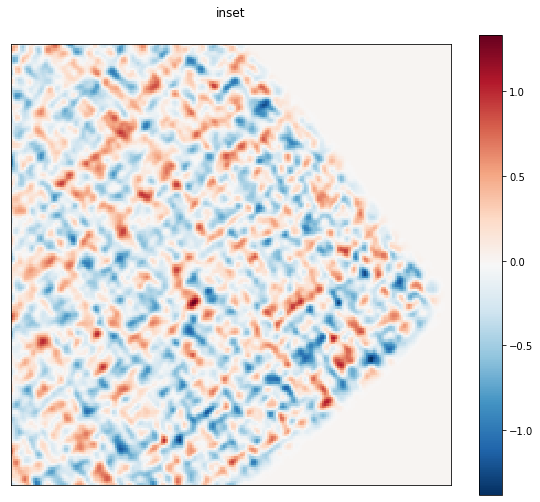

In [39]:
plotframe({"inset" : (teb_unlensed["B"].get_real().get_rmap()['T'] / G3Units.uK * sim_reader.get_pixel_mask())[700:900, 1980:2180]},
          size=(8,7), layout=111)

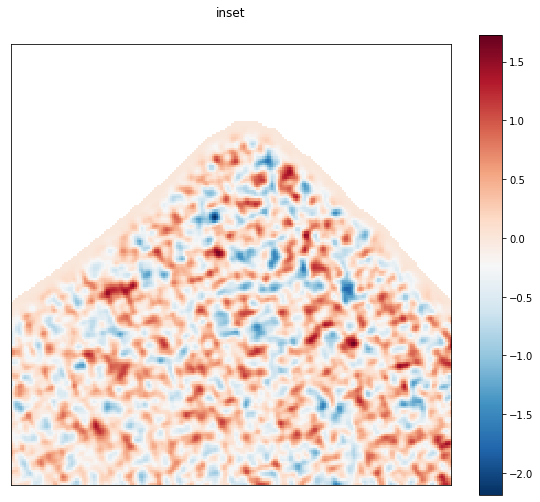

In [57]:
plotframe({"inset" : (b_big_flat * spt_mask)[500:700, 1480:1680]},
          size=(8,7), layout=111)

In [ ]:
plotframe({"inset" : (teb_unlensed["B"].get_real().get_rmap()['T'] / G3Units.uK * sim_reader.get_pixel_mask())[150:350, 1480:1680]},
          size=(8,7), layout=111)

Since both effects get better if you increase the resolution, the gradient calculation performed in both functions may be the cause of this.